# Notebook 14 — Validation Protocol Audit and Model Selection

本 Notebook 审计前期实验中 Validation 数据的使用方式，并根据 **Week 64–77** 重新对候选 feature subsets 与 hyperparameter configurations 进行选择。Week 78–91 OOT 保留为独立的最终时间外测试窗口。

## 0.1 数据窗口与用途

| 时间段 | 本阶段用途 |
|---|---|
| Week 0–63 | 模型训练、F1–F4 development folds、候选生成和稳健性分析 |
| Week 64–77 | Feature subset 与 hyperparameter selection；**不是最终无偏测试集** |
| Week 78–91 | OOT，当前 Notebook 不读取 |

## 0.2 前期结果的可比性审计

Notebook 13 比较了三阶段模型，但原始 NB7 LightGBM baseline 曾使用 Week 64–77 做 early stopping，后续 NB8–12 则把该时间段留出，只在 Week 0–63 内部选择候选。这种 **Validation exposure / model-selection protocol 不一致**，使得不同阶段的 Validation AUC 不能直接视为完全公平的对照。

这不是将未来标签加入训练矩阵的 target leakage；它属于模型选择过程中验证集信息使用程度不同的问题。因此，原始 Tree baseline 相对后续模型更高的 AUC，不能单独证明特征筛选或调参无效。

## 0.3 本 Notebook 的协议与后续边界

本阶段采用以下工作流：

```text
Development Week 0–63
→ 上游候选生成 + F1–F4 时间稳健性评估
           ↓
Validation Week 64–77
→ 在候选池内选择 feature subset
→ 在所选特征空间内选择 hyperparameters
           ↓
Freeze Selected Configurations
           ↓
OOT Week 78–91
→ 后续独立评估（本 Notebook 未执行）
```

**方法限制：** NB14 在同一 Validation 窗口上按顺序筛选特征集与超参数，因而存在一定程度的 validation-set selection bias。该窗口的最佳得分应解释为 *model-selection performance*，而非独立泛化性能估计。候选范围及选择规则应在最终 OOT 评估前固定；OOT 结果不能被用于进一步调参后又作为同一次独立测试成绩。


In [1]:
#@title 第 1 步：环境、路径和上游结果
from pathlib import Path
from collections import Counter
import gc, json, math, shutil, hashlib, warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import lightgbm as lgb
import matplotlib.pyplot as plt

from scipy import sparse
from scipy.optimize import minimize
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.preprocessing import OneHotEncoder, SplineTransformer
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/HomeCredit_Project")
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"

NB14_DIR = ARTIFACT_ROOT / "nb14" / "final"
NB14_CKPT = ARTIFACT_ROOT / "nb14" / "checkpoints_v1"
NB14_DIR.mkdir(parents=True, exist_ok=True)
NB14_CKPT.mkdir(parents=True, exist_ok=True)

ID_COL = "case_id"
TARGET_COL = "target"
WEEK_COL = "WEEK_NUM"
SEED = 42

def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def find_dir(required, preferred):
    required = set(required)

    for p in preferred:
        p = Path(p)
        if p.exists():
            names = {x.name for x in p.iterdir()}
            if required.issubset(names):
                return p

    first = sorted(required)[0]
    for f in PROJECT_ROOT.rglob(first):
        p = f.parent
        names = {x.name for x in p.iterdir()}
        if required.issubset(names):
            return p

    raise FileNotFoundError(f"找不到完整上游目录：{sorted(required)}")

NB5_DIR = find_dir(
    {"train_clean.parquet", "validation_clean.parquet"},
    [
        ARTIFACT_ROOT / "nb05" / "final",
        ARTIFACT_ROOT / "nb05",
        PROJECT_ROOT / "clean_split",
    ],
)

NB7_DIR = find_dir(
    {
        "nb7_candidate_features.csv",
        "numeric_preprocessing_stats.csv",
        "categorical_encoding_rules.json",
    },
    [
        ARTIFACT_ROOT / "nb07" / "final",
        ARTIFACT_ROOT / "nb07",
        PROJECT_ROOT / "reports" / "reference_model",
    ],
)

NB9_DIR = find_dir(
    {"tree_rankings.json", "lr_rankings.json", "nb9_ranking_config.json"},
    [
        ARTIFACT_ROOT / "nb09" / "final",
        ARTIFACT_ROOT / "nb09",
    ],
)

# NB11 只用于复用已有 Local FE 规则。
# 如果最终 LR subset 改变，只保留 source 全部属于新 subset 的 FE。
NB11_DIR = ARTIFACT_ROOT / "nb11" / "final"

tree_routes = load_json(NB9_DIR / "tree_rankings.json")
lr_routes = load_json(NB9_DIR / "lr_rankings.json")

catalog = pd.read_csv(NB7_DIR / "nb7_candidate_features.csv")
all_features = catalog["feature"].astype(str).tolist()
dtype_map = catalog.set_index("feature")["dtype_family"].to_dict()

numeric_stats = pd.read_csv(
    NB7_DIR / "numeric_preprocessing_stats.csv"
).set_index("feature")

cat_rules_raw = load_json(
    NB7_DIR / "categorical_encoding_rules.json"
)

LOCAL_CACHE = Path("/content/homecredit_nb14")
LOCAL_CACHE.mkdir(parents=True, exist_ok=True)

def cache_file(src):
    src = Path(src)
    dst = LOCAL_CACHE / src.name
    if not dst.exists() or dst.stat().st_size != src.stat().st_size:
        shutil.copy2(src, dst)
    return dst

TRAIN_PATH = cache_file(NB5_DIR / "train_clean.parquet")
VALID_PATH = cache_file(NB5_DIR / "validation_clean.parquet")

train_pq = pq.ParquetFile(TRAIN_PATH)
valid_pq = pq.ParquetFile(VALID_PATH)

train_meta = pd.read_parquet(
    TRAIN_PATH,
    columns=[ID_COL, WEEK_COL, TARGET_COL],
)
valid_meta = pd.read_parquet(
    VALID_PATH,
    columns=[ID_COL, WEEK_COL, TARGET_COL],
)

assert train_meta[WEEK_COL].between(0, 63).all()
assert valid_meta[WEEK_COL].between(64, 77).all()

print("Train Week：", train_meta[WEEK_COL].min(), "-", train_meta[WEEK_COL].max())
print("Validation Week：", valid_meta[WEEK_COL].min(), "-", valid_meta[WEEK_COL].max())
print("OOT 78–91：本册不读取")


Mounted at /content/drive
Train Week： 0 - 63
Validation Week： 64 - 77
OOT 78–91：本册不读取


## 1. 预定义候选范围

### 1.1 扩展后的 Feature Subset Shortlist

在 NB10 已评估的候选中，除了进入 F1–F4 的 finalists 与 full-feature baseline，本阶段也纳入此前表现较好的其他路径和相邻特征规模。

考虑到：

```text
1. Tree 在 GPU 上训练较快；
2. 前期使用 Validation 数据的协议存在不一致，需要明确后续模型选择规则；
3. NB10 中还有一些 Stage-1 / Fine Search 表现很有竞争力，
   但因为 Pareto / full-temporal budget 没有进入最后四个 finalists；
```

本版把 Tree feature shortlist 明显扩大。

### Tree：22 个 feature candidates

包括：

```text
Full features

Relevance：
450 / 500 / 550 / 600 / 700 / 800

Model Gain：
200 / 300 / 400 / 600 / 800

Temporal Relevance：
200

Redundancy-aware：
100 / 300 / 600 / 800

Consensus：
500 / 700 / 800

Interaction Relevance：
600 / 700
```

这里仍然不是重新做 Notebook 10 的全量搜索。

这些候选全部来自：

```text
NB10 已经真正搜索过的 route / depth
+
原 F1–F4 finalists
+
finalist 附近的 fine-search 邻域
+
NB10 Stage-1 中表现很有竞争力的高分区域
```

这一扩展旨在降低：

```text
“因为 F1–F4 shortlist 太窄，
导致真正 Validation winner 根本没有机会进入比较”
```

导致候选空间覆盖不足的风险。

### LR：8 个 feature candidates

LR 计算成本更高，因此保持相对紧凑：

```text
Full features

Relevance：
550 / 600 / 650

Redundancy-aware：
100 / 150 / 1000

LR Consensus：
500
```

其中仍然保留 NB10 原始 F1–F4 finalists，同时加入少量邻近深度。

---

### 参数阶段

特征选完以后，再使用 Notebook 12 的完整参数候选：

```text
LR：5 个 L2 + LBFGS 的 C
Tree：12 个有方向的 LightGBM 配置
```

因此：

```text
先在 Validation 上选 feature space
→ 再在选中的 feature space 上调参数
```

仍然不做：

```text
22 个 Tree feature sets
×
12 个 Tree parameter configs
```

这种完整笛卡尔积。

该搜索是有限候选集上的两阶段选择，而不是全参数组合枚举。由于同一 Validation 窗口用于选择，结果仍须通过独立 OOT 测试。

> 注意：Week 64–77 已经正式承担 model selection，因此本册结束后不再继续根据 Validation 结果扩展候选；最终无偏评价仍然只看 Week 78–91 OOT。


In [2]:
#@title 第 2 步：重建 NB10 finalists + NB12 全部参数候选

# ------------------------------------------------------------
# NB10-derived feature shortlist
# ------------------------------------------------------------
#
# Tree:
#   - 原 F1–F4 finalists
#   - Full baseline
#   - Relevance finalist 的 ±50 / nearby depth
#   - NB10 Stage-1 中其他 route 的高竞争力区域
#
# LR:
#   - 原 F1–F4 finalists
#   - Full baseline
#   - 少量邻近 depth
#
# 所有这些 route/depth 都来自 NB10 实际搜索过的空间，
# 不是在 Validation 上临时发明的新搜索路线。
# ------------------------------------------------------------

TREE_SHORTLIST_SPECS = [
    # Relevance route
    ("tree__relevance__n450", "relevance", 450),
    ("tree__relevance__n500", "relevance", 500),
    ("tree__relevance__n550", "relevance", 550),
    ("tree__relevance__n600", "relevance", 600),
    ("tree__relevance__n700", "relevance", 700),
    ("tree__relevance__n800", "relevance", 800),

    # Model Gain route
    ("tree__model_gain__n200", "model_gain", 200),
    ("tree__model_gain__n300", "model_gain", 300),
    ("tree__model_gain__n400", "model_gain", 400),
    ("tree__model_gain__n600", "model_gain", 600),
    ("tree__model_gain__n800", "model_gain", 800),

    # Temporal finalist
    ("tree__temporal_relevance__n200", "temporal_relevance", 200),

    # Redundancy-aware route
    (
        "tree__redundancy_aware__boundary_n100",
        "redundancy_aware",
        100,
    ),
    ("tree__redundancy_aware__n300", "redundancy_aware", 300),
    ("tree__redundancy_aware__n600", "redundancy_aware", 600),
    ("tree__redundancy_aware__n800", "redundancy_aware", 800),

    # Consensus route
    ("tree__consensus__n500", "consensus", 500),
    ("tree__consensus__n700", "consensus", 700),
    ("tree__consensus__n800", "consensus", 800),

    # Interaction route
    (
        "tree__interaction_relevance__n600",
        "interaction_relevance",
        600,
    ),
    (
        "tree__interaction_relevance__n700",
        "interaction_relevance",
        700,
    ),
]

LR_SHORTLIST_SPECS = [
    # Relevance finalist + nearby fine-search depths
    ("lr__relevance__n550", "relevance", 550),
    ("lr__relevance__n600", "relevance", 600),
    ("lr__relevance__n650", "relevance", 650),

    # Strong boundary solution + nearby point + upper boundary
    (
        "lr__redundancy_aware__boundary_n100",
        "redundancy_aware",
        100,
    ),
    ("lr__redundancy_aware__n150", "redundancy_aware", 150),
    (
        "lr__redundancy_aware__boundary_n1000",
        "redundancy_aware",
        1000,
    ),

    # Original temporal finalist from the consensus route
    ("lr__lr_consensus__n500", "lr_consensus", 500),
]


def build_shortlist(route_dict, specs, full_name):
    candidates = {
        full_name: list(all_features)
    }

    skipped = []

    for name, route, k in specs:
        if route not in route_dict:
            skipped.append(
                (name, f"route_missing:{route}")
            )
            continue

        ordered = list(route_dict[route])

        if len(ordered) < k:
            skipped.append(
                (
                    name,
                    f"route_too_short:{len(ordered)}<{k}",
                )
            )
            continue

        candidates[name] = ordered[:k]

    if skipped:
        print("以下 shortlist candidate 被跳过：")
        for item in skipped:
            print(" ", item)

    return candidates


tree_feature_candidates = build_shortlist(
    tree_routes,
    TREE_SHORTLIST_SPECS,
    "tree__full",
)

lr_feature_candidates = build_shortlist(
    lr_routes,
    LR_SHORTLIST_SPECS,
    "lr__full",
)

# ------------------------------------------------------------
# Feature-stage fixed baseline configs
# 与 NB10 的固定 evaluator 保持同一思想：
# 比 feature 时不同时调模型。
# ------------------------------------------------------------
LR_FEATURE_BASE = {
    "epochs": 3,
    "alpha": 1e-4,
    "eta0": 0.01,
    "average": True,
}

TREE_BASE = {
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_data_in_leaf": 20,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l1": 0.0,
    "lambda_l2": 1.0,
    "num_boost_round": 300,
}

# ------------------------------------------------------------
# NB12 FAST-LR 完整参数候选
# ------------------------------------------------------------
LR_PARAM_CANDIDATES = [
    {"candidate": "lr_l2_lbfgs_c0p03", "solver": "lbfgs", "penalty": "l2", "C": 0.03, "max_iter": 1000, "tol": 1e-4},
    {"candidate": "lr_l2_lbfgs_c0p1",  "solver": "lbfgs", "penalty": "l2", "C": 0.1,  "max_iter": 1000, "tol": 1e-4},
    {"candidate": "lr_l2_lbfgs_c0p3",  "solver": "lbfgs", "penalty": "l2", "C": 0.3,  "max_iter": 1000, "tol": 1e-4},
    {"candidate": "lr_l2_lbfgs_c1",    "solver": "lbfgs", "penalty": "l2", "C": 1.0,  "max_iter": 1000, "tol": 1e-4},
    {"candidate": "lr_l2_lbfgs_c3",    "solver": "lbfgs", "penalty": "l2", "C": 3.0,  "max_iter": 1000, "tol": 1e-4},
]

def tree_cfg(candidate, **updates):
    cfg = dict(TREE_BASE)
    cfg.update(updates)
    cfg["candidate"] = candidate
    return cfg

TREE_PARAM_CANDIDATES = [
    tree_cfg("tree_baseline"),
    tree_cfg("tree_leaves15_leaf50", num_leaves=15, min_data_in_leaf=50),
    tree_cfg("tree_leaves31_leaf50", min_data_in_leaf=50),
    tree_cfg("tree_leaves31_leaf100", min_data_in_leaf=100),
    tree_cfg("tree_leaves63_leaf50", num_leaves=63, min_data_in_leaf=50),
    tree_cfg("tree_leaves63_leaf100", num_leaves=63, min_data_in_leaf=100),
    tree_cfg("tree_feature60", feature_fraction=0.6),
    tree_cfg("tree_bag60", bagging_fraction=0.6),
    tree_cfg("tree_subsample_both", feature_fraction=0.6, bagging_fraction=0.7),
    tree_cfg("tree_l2_5", lambda_l2=5.0),
    tree_cfg("tree_l1_1_l2_1", lambda_l1=1.0, lambda_l2=1.0),
    tree_cfg("tree_slow500", learning_rate=0.03, num_boost_round=500),
]

print(f"Tree feature candidates：{len(tree_feature_candidates)}")
for k, v in tree_feature_candidates.items():
    print(f"  {k}: {len(v)} features")

print(f"\nLR feature candidates：{len(lr_feature_candidates)}")
for k, v in lr_feature_candidates.items():
    print(f"  {k}: {len(v)} features")

print("\nLR parameter candidates：", len(LR_PARAM_CANDIDATES))
print("Tree parameter candidates：", len(TREE_PARAM_CANDIDATES))


Tree feature candidates：22
  tree__full: 1209 features
  tree__relevance__n450: 450 features
  tree__relevance__n500: 500 features
  tree__relevance__n550: 550 features
  tree__relevance__n600: 600 features
  tree__relevance__n700: 700 features
  tree__relevance__n800: 800 features
  tree__model_gain__n200: 200 features
  tree__model_gain__n300: 300 features
  tree__model_gain__n400: 400 features
  tree__model_gain__n600: 600 features
  tree__model_gain__n800: 800 features
  tree__temporal_relevance__n200: 200 features
  tree__redundancy_aware__boundary_n100: 100 features
  tree__redundancy_aware__n300: 300 features
  tree__redundancy_aware__n600: 600 features
  tree__redundancy_aware__n800: 800 features
  tree__consensus__n500: 500 features
  tree__consensus__n700: 700 features
  tree__consensus__n800: 800 features
  tree__interaction_relevance__n600: 600 features
  tree__interaction_relevance__n700: 700 features

LR feature candidates：8
  lr__full: 1209 features
  lr__relevance__n550

In [3]:
#@title Model Evaluation and Checkpoint Utilities
MISSING = "__HC_MISSING__"
RARE = "__HC_RARE__"

# ============================================================
# Checkpoint
# ============================================================
def stable_hash(payload):
    raw = json.dumps(
        payload,
        sort_keys=True,
        ensure_ascii=False,
        default=str,
    ).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()[:18]

def pred_ckpt(branch, payload):
    return NB14_CKPT / f"{branch}__{stable_hash(payload)}.parquet"

def save_pred(path, pred):
    frame = valid_meta[[ID_COL, WEEK_COL, TARGET_COL]].copy()
    frame["prediction"] = np.asarray(pred, np.float32)
    frame.to_parquet(path, index=False)

def load_pred(path):
    return pd.read_parquet(path)

# ============================================================
# Metrics
# ============================================================
def calibration_metrics(y, p):
    y = np.asarray(y, float)
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p))

    def nll(beta):
        eta = beta[0] + beta[1] * lp
        return float(
            np.sum(np.logaddexp(0, eta) - y * eta)
        )

    res = minimize(
        nll,
        np.array([0.0, 1.0]),
        method="L-BFGS-B",
    )

    if res.success:
        intercept = float(res.x[0])
        slope = float(res.x[1])
    else:
        intercept = np.nan
        slope = np.nan

    obs = float(np.mean(y))
    exp = float(np.mean(p))
    oe = obs / exp if exp > 0 else np.nan

    return intercept, slope, oe

def evaluate_prediction(name, frame, feature_count=None):
    y = frame[TARGET_COL].to_numpy(np.int8)
    p = frame["prediction"].to_numpy(float)
    w = frame[WEEK_COL].to_numpy(int)

    auc = float(roc_auc_score(y, p))

    weekly = []
    for week in sorted(np.unique(w)):
        m = w == week
        if len(np.unique(y[m])) < 2:
            continue
        weekly.append(
            (week, float(roc_auc_score(y[m], p[m])))
        )

    wt = pd.DataFrame(weekly, columns=["week", "auc"])
    intercept, slope, oe = calibration_metrics(y, p)

    row = {
        "candidate": name,
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "worst_week_AUC": float(wt["auc"].min()),
        "weekly_AUC_sd": float(wt["auc"].std(ddof=0)),
        "weekly_AUC_slope": float(
            np.polyfit(wt["week"], wt["auc"], 1)[0]
        ),
        "calibration_slope": slope,
        "calibration_intercept": intercept,
        "O_E": oe,
    }

    if feature_count is not None:
        row["feature_count"] = int(feature_count)

    return row, wt

# ============================================================
# LR preprocessing
# ============================================================
LR_STATE_CACHE = {}

def make_lr_state(features):
    key = tuple(features)
    if key in LR_STATE_CACHE:
        return LR_STATE_CACHE[key]

    nums = [
        f for f in features
        if dtype_map.get(f) == "numeric"
    ]
    cats = [
        f for f in features
        if dtype_map.get(f) in {"categorical", "boolean"}
    ]

    # 防止极少数字段 family 缺失
    known = set(nums) | set(cats)
    nums.extend([f for f in features if f not in known])

    st = numeric_stats.reindex(nums)

    med = (
        st["median"].fillna(0).to_numpy(np.float32)
        if nums else np.array([], np.float32)
    )
    mean = (
        st["mean_after_imputation"].fillna(0).to_numpy(np.float32)
        if nums else np.array([], np.float32)
    )
    scale = (
        st["scale_after_imputation"].fillna(1).to_numpy(np.float32)
        if nums else np.array([], np.float32)
    )
    scale[~np.isfinite(scale) | (np.abs(scale) < 1e-12)] = 1.0

    miss_feats = []
    if nums and "has_missing" in st.columns:
        miss_feats = (
            st.index[
                st["has_missing"]
                .fillna(False)
                .astype(bool)
            ].tolist()
        )
    miss_idx = [nums.index(f) for f in miss_feats]

    cat_lists = []
    kept = {}

    for f in cats:
        if f not in cat_rules_raw:
            values = [MISSING, RARE]
        else:
            values = [str(x) for x in cat_rules_raw[f]]
            if not values:
                values = [MISSING, RARE]
        cat_lists.append(values)
        kept[f] = set(values)

    if cats:
        kw = dict(
            categories=cat_lists,
            handle_unknown="ignore",
            dtype=np.float32,
        )
        try:
            enc = OneHotEncoder(
                sparse_output=True,
                **kw,
            )
        except TypeError:
            enc = OneHotEncoder(
                sparse=True,
                **kw,
            )

        dummy = pd.DataFrame({
            f: [cat_lists[i][0]]
            for i, f in enumerate(cats)
        })
        enc.fit(dummy)
    else:
        enc = None

    state = {
        "features": list(features),
        "nums": nums,
        "cats": cats,
        "med": med,
        "mean": mean,
        "scale": scale,
        "miss_idx": miss_idx,
        "kept": kept,
        "enc": enc,
    }
    LR_STATE_CACHE[key] = state
    return state

def transform_lr(frame, state):
    n = len(frame)

    if state["nums"]:
        Xn = frame[state["nums"]].to_numpy(
            dtype=np.float32,
            na_value=np.nan,
        )
        miss = ~np.isfinite(Xn)

        if miss.any():
            r, c = np.where(miss)
            Xn[r, c] = state["med"][c]

        Xn = (
            Xn - state["mean"]
        ) / state["scale"]

        Xn = sparse.csr_matrix(
            Xn,
            dtype=np.float32,
        )

        Xm = (
            sparse.csr_matrix(
                miss[:, state["miss_idx"]].astype(np.float32)
            )
            if state["miss_idx"]
            else sparse.csr_matrix((n, 0), dtype=np.float32)
        )
    else:
        Xn = sparse.csr_matrix((n, 0), dtype=np.float32)
        Xm = sparse.csr_matrix((n, 0), dtype=np.float32)

    if state["cats"]:
        mapped = {}
        for f in state["cats"]:
            s = (
                frame[f]
                .astype("string")
                .fillna(MISSING)
            )
            s = s.where(
                s.isin(state["kept"][f]),
                RARE,
            )
            mapped[f] = s.astype(object)

        Xc = state["enc"].transform(
            pd.DataFrame(mapped, index=frame.index)
        )
    else:
        Xc = sparse.csr_matrix((n, 0), dtype=np.float32)

    return sparse.hstack(
        [Xn, Xm, Xc],
        format="csr",
        dtype=np.float32,
    )

def fit_sgd_lr(features):
    state = make_lr_state(features)

    model = SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=LR_FEATURE_BASE["alpha"],
        learning_rate="constant",
        eta0=LR_FEATURE_BASE["eta0"],
        shuffle=False,
        average=LR_FEATURE_BASE["average"],
        random_state=SEED,
    )

    first = True

    for epoch in range(LR_FEATURE_BASE["epochs"]):
        groups = np.arange(train_pq.num_row_groups)
        np.random.default_rng(SEED + epoch).shuffle(groups)

        for rg in groups:
            frame = train_pq.read_row_group(
                int(rg),
                columns=[TARGET_COL, *features],
                use_threads=True,
            ).to_pandas()

            frame = frame.sample(
                frac=1.0,
                random_state=SEED + epoch * 1000 + int(rg),
            ).reset_index(drop=True)

            y = frame[TARGET_COL].to_numpy(np.int8)
            X = transform_lr(frame, state)

            if first:
                model.partial_fit(
                    X,
                    y,
                    classes=np.array([0, 1], np.int8),
                )
                first = False
            else:
                model.partial_fit(X, y)

            del frame, X, y
            gc.collect()

    return model, state

def predict_lr_stream(model, state, features):
    out = []

    for rg in range(valid_pq.num_row_groups):
        frame = valid_pq.read_row_group(
            rg,
            columns=features,
            use_threads=True,
        ).to_pandas()

        X = transform_lr(frame, state)
        out.append(
            model.predict_proba(X)[:, 1].astype(np.float32)
        )

        del frame, X
        gc.collect()

    return np.concatenate(out)

# ============================================================
# NB11 compatible Local FE
# ============================================================
def num_array(frame, f):
    return pd.to_numeric(
        frame[f],
        errors="coerce",
    ).to_numpy(float)

def raw_fe(frame, spec, state):
    fam = spec["family"]
    src = spec["sources"]

    if fam in {"signed_log1p", "winsor"}:
        x = num_array(frame, src[0])

    if fam == "signed_log1p":
        return np.sign(x) * np.log1p(np.abs(x))

    if fam == "winsor":
        return np.clip(
            x,
            state["lower"],
            state["upper"],
        )

    if fam == "ratio":
        a = num_array(frame, src[0])
        b = num_array(frame, src[1])
        eps = float(
            spec.get("params", {}).get("epsilon", 1e-6)
        )
        return a / np.where(
            np.abs(b) < eps,
            np.nan,
            b,
        )

    if fam == "relative_change":
        a = num_array(frame, src[0])
        b = num_array(frame, src[1])
        eps = float(
            spec.get("params", {}).get("epsilon", 1e-6)
        )
        return (a - b) / np.maximum(np.abs(b), eps)

    if fam == "product":
        return (
            num_array(frame, src[0])
            * num_array(frame, src[1])
        )

    raise ValueError(f"未知 Local FE family：{fam}")

def fit_fe_state(frame, spec):
    fam = spec["family"]
    params = dict(spec.get("params", {}))
    src = list(spec["sources"])

    state = {
        "family": fam,
        "sources": src,
        "params": params,
    }

    if fam == "winsor":
        x = num_array(frame, src[0])
        v = x[np.isfinite(x)]
        if len(v):
            state["lower"] = float(
                np.quantile(v, params["lower_q"])
            )
            state["upper"] = float(
                np.quantile(v, params["upper_q"])
            )
        else:
            state["lower"] = 0.0
            state["upper"] = 0.0

    elif fam == "qbin":
        x = num_array(frame, src[0])
        v = x[np.isfinite(x)]

        if len(v):
            qs = np.linspace(
                0,
                1,
                int(params["n_bins"]) + 1,
            )[1:-1]
            edges = np.unique(np.quantile(v, qs))
        else:
            edges = np.array([])

        state["edges"] = edges.tolist()

    elif fam == "spline":
        x = num_array(frame, src[0])
        v = x[np.isfinite(x)]
        med = float(np.median(v)) if len(v) else 0.0

        x2 = np.where(
            np.isfinite(x),
            x,
            med,
        ).reshape(-1, 1)

        tr = SplineTransformer(
            n_knots=int(params["n_knots"]),
            degree=int(params["degree"]),
            knots="quantile",
            include_bias=False,
        )
        tr.fit(x2)

        state["median"] = med
        state["transformer"] = tr

    if fam in {
        "signed_log1p",
        "winsor",
        "ratio",
        "relative_change",
        "product",
    }:
        r = raw_fe(frame, spec, state)
        v = r[np.isfinite(r)]

        med = float(np.median(v)) if v.size else 0.0
        r2 = np.where(np.isfinite(r), r, med)

        mean = float(np.mean(r2))
        scale = float(np.std(r2))

        if not np.isfinite(scale) or scale < 1e-12:
            scale = 1.0

        state.update(
            out_median=med,
            out_mean=mean,
            out_scale=scale,
        )

    return state

def transform_fe(frame, spec, state):
    fam = spec["family"]

    if fam == "qbin":
        x = num_array(frame, spec["sources"][0])
        edges = np.asarray(state["edges"], float)

        bins = np.digitize(x, edges)
        bins[~np.isfinite(x)] = len(edges) + 1

        rows = np.arange(len(frame))
        return sparse.csr_matrix(
            (
                np.ones(len(frame), np.float32),
                (rows, bins),
            ),
            shape=(len(frame), len(edges) + 2),
            dtype=np.float32,
        )

    if fam == "spline":
        x = num_array(frame, spec["sources"][0])
        x2 = np.where(
            np.isfinite(x),
            x,
            state["median"],
        ).reshape(-1, 1)

        return sparse.csr_matrix(
            state["transformer"]
            .transform(x2)
            .astype(np.float32)
        )

    r = raw_fe(frame, spec, state)
    r = np.where(
        np.isfinite(r),
        r,
        state["out_median"],
    )

    z = (
        (r - state["out_mean"])
        / state["out_scale"]
    ).astype(np.float32)

    return sparse.csr_matrix(
        z.reshape(-1, 1)
    )

def read_all(pq_file, columns):
    return pd.concat(
        [
            pq_file
            .read_row_group(
                i,
                columns=columns,
                use_threads=True,
            )
            .to_pandas()
            for i in range(pq_file.num_row_groups)
        ],
        ignore_index=True,
    )

def build_lr_param_design(
    selected_features,
    compatible_specs,
):
    req = set(selected_features)
    for spec in compatible_specs:
        req.update(spec["sources"])
    req = sorted(req)

    train_df = read_all(
        train_pq,
        [TARGET_COL, *req],
    )
    valid_df = read_all(
        valid_pq,
        req,
    )

    base_state = make_lr_state(selected_features)

    tr_blocks = [
        transform_lr(train_df, base_state)
    ]
    va_blocks = [
        transform_lr(valid_df, base_state)
    ]

    for spec in compatible_specs:
        st = fit_fe_state(train_df, spec)
        tr_blocks.append(
            transform_fe(train_df, spec, st)
        )
        va_blocks.append(
            transform_fe(valid_df, spec, st)
        )

    Xtr = sparse.hstack(
        tr_blocks,
        format="csr",
        dtype=np.float32,
    )
    Xva = sparse.hstack(
        va_blocks,
        format="csr",
        dtype=np.float32,
    )
    ytr = train_df[TARGET_COL].to_numpy(np.int8)

    del train_df, valid_df, tr_blocks, va_blocks
    gc.collect()

    return Xtr, ytr, Xva

# ============================================================
# Tree
# ============================================================
TREE_MISSING = "__MISSING__"
TREE_RARE = "__RARE__"
TREE_RULE_CACHE = {}

def tree_types(features):
    nums = [
        f for f in features
        if dtype_map.get(f) == "numeric"
    ]
    cats = [
        f for f in features
        if dtype_map.get(f) in {"categorical", "boolean"}
    ]

    known = set(nums) | set(cats)
    nums.extend([f for f in features if f not in known])

    return nums, cats

def learn_tree_rules(features):
    key = tuple(features)

    if key in TREE_RULE_CACHE:
        return TREE_RULE_CACHE[key]

    _, cats = tree_types(features)

    counters = {
        f: Counter()
        for f in cats
    }

    for rg in range(train_pq.num_row_groups):
        if not cats:
            break

        frame = train_pq.read_row_group(
            rg,
            columns=cats,
            use_threads=True,
        ).to_pandas()

        for f in cats:
            s = (
                frame[f]
                .astype("string")
                .fillna(TREE_MISSING)
            )
            counters[f].update({
                str(k): int(v)
                for k, v in s.value_counts().items()
            })

        del frame
        gc.collect()

    rules = {}

    for f in cats:
        normal = [
            (k, v)
            for k, v in counters[f].items()
            if k != TREE_MISSING
        ]
        normal.sort(
            key=lambda x: (-x[1], x[0])
        )

        kept = [
            k for k, _ in normal[:98]
        ]

        categories = [
            *kept,
            TREE_MISSING,
            TREE_RARE,
        ]

        rules[f] = {
            "categories": categories,
            "kept_set": set(categories),
        }

    TREE_RULE_CACHE[key] = rules
    return rules

class TreeSeq(lgb.Sequence):
    batch_size = 4096

    def __init__(self, pq_file, features, rules):
        self.pq_file = pq_file
        self.nums, self.cats = tree_types(features)
        self.features = [*self.nums, *self.cats]
        self.rules = rules

        sizes = np.array(
            [
                pq_file.metadata.row_group(i).num_rows
                for i in range(pq_file.num_row_groups)
            ],
            dtype=np.int64,
        )

        self.starts = np.concatenate(
            [[0], np.cumsum(sizes)]
        )
        self.total = int(self.starts[-1])

        self._rg = None
        self._mat = None

    def __len__(self):
        return self.total

    def _load(self, rg):
        frame = self.pq_file.read_row_group(
            rg,
            columns=self.features,
            use_threads=True,
        ).to_pandas()

        if self.nums:
            num = (
                frame[self.nums]
                .apply(pd.to_numeric, errors="coerce")
                .to_numpy(
                    dtype=np.float64,
                    na_value=np.nan,
                )
            )
        else:
            num = np.empty(
                (len(frame), 0),
                dtype=np.float64,
            )

        cat_parts = []

        for f in self.cats:
            s = (
                frame[f]
                .astype("string")
                .fillna(TREE_MISSING)
            )

            rule = self.rules[f]
            s = s.where(
                s.isin(rule["kept_set"]),
                TREE_RARE,
            )

            codes = pd.Categorical(
                s,
                categories=rule["categories"],
            ).codes.astype(np.float64)

            cat_parts.append(codes)

        if cat_parts:
            mat = np.hstack(
                [num, np.column_stack(cat_parts)]
            )
        else:
            mat = num

        del frame
        gc.collect()

        return np.asarray(
            mat,
            np.float64,
            order="C",
        )

    def _get(self, rg):
        if self._rg != rg:
            self._mat = self._load(rg)
            self._rg = rg
        return self._mat

    def _loc(self, idx):
        rg = int(
            np.searchsorted(
                self.starts[1:],
                idx,
                side="right",
            )
        )
        return rg, int(idx - self.starts[rg])

    def __getitem__(self, idx):
        if isinstance(idx, (int, np.integer)):
            rg, loc = self._loc(int(idx))
            return self._get(rg)[loc]

        if isinstance(idx, slice):
            start = 0 if idx.start is None else int(idx.start)
            stop = len(self) if idx.stop is None else int(idx.stop)

            parts = []
            cur = start

            while cur < stop:
                rg, loc = self._loc(cur)
                mat = self._get(rg)
                take = min(
                    len(mat) - loc,
                    stop - cur,
                )
                parts.append(
                    mat[loc:loc + take]
                )
                cur += take

            return (
                parts[0]
                if len(parts) == 1
                else np.vstack(parts)
            )

        return np.stack([
            self[int(i)]
            for i in idx
        ])

def fit_tree(features, config):
    rules = learn_tree_rules(features)
    seq = TreeSeq(
        train_pq,
        features,
        rules,
    )

    y = train_meta[TARGET_COL].to_numpy(np.int8)
    cat_idx = list(
        range(
            len(seq.nums),
            len(seq.features),
        )
    )

    ds = lgb.Dataset(
        seq,
        label=y,
        feature_name=seq.features,
        categorical_feature=cat_idx,
        free_raw_data=True,
        params={
            "bin_construct_sample_cnt": 50_000,
            "max_bin": 63,
            "data_random_seed": SEED,
        },
    )

    params = {
        "objective": "binary",
        "metric": "auc",
        "learning_rate": float(config["learning_rate"]),
        "num_leaves": int(config["num_leaves"]),
        "min_data_in_leaf": int(config["min_data_in_leaf"]),
        "feature_fraction": float(config["feature_fraction"]),
        "bagging_fraction": float(config["bagging_fraction"]),
        "bagging_freq": int(config["bagging_freq"]),
        "lambda_l1": float(config["lambda_l1"]),
        "lambda_l2": float(config["lambda_l2"]),
        "seed": SEED,
        "device_type": "gpu",
        "max_bin": 63,
        "verbosity": -1,
    }

    model = lgb.train(
        params,
        ds,
        num_boost_round=int(config["num_boost_round"]),
    )

    return model, rules

def predict_tree(model, features, rules):
    seq = TreeSeq(
        valid_pq,
        features,
        rules,
    )

    out = []

    for start in range(0, len(seq), 8192):
        out.append(
            model.predict(
                seq[start:min(start + 8192, len(seq))]
            )
        )

    return np.concatenate(out)

# ============================================================
# Common evaluators with checkpoints
# ============================================================
def run_lr_feature_candidate(name, features):
    payload = {
        "stage": "lr_feature",
        "name": name,
        "features": features,
        "config": LR_FEATURE_BASE,
    }

    path = pred_ckpt("lr_feature", payload)

    if path.exists():
        return load_pred(path)

    print("训练 LR feature candidate：", name)

    model, state = fit_sgd_lr(features)
    p = predict_lr_stream(
        model,
        state,
        features,
    )

    save_pred(path, p)

    del model, state, p
    gc.collect()

    return load_pred(path)

def run_tree_candidate(name, features, config):
    payload = {
        "stage": "tree",
        "name": name,
        "features": features,
        "config": config,
    }

    path = pred_ckpt("tree", payload)

    if path.exists():
        return load_pred(path)

    print("训练 Tree candidate：", name)

    model, rules = fit_tree(
        features,
        config,
    )
    p = predict_tree(
        model,
        features,
        rules,
    )

    save_pred(path, p)

    del model, p
    gc.collect()

    return load_pred(path)


## 实验 1：候选特征集的 Validation 比较

### 实验目的

回答三个问题：

```text
1. Notebook 10 原 F1–F4 finalists
   到真正 Validation 64–77 上还能不能保持优势？

2. 原 shortlist 是否压缩得太早，
   导致一些在 NB10 Stage-1 / Fine Search 很有竞争力的方案没有进入最终比较？

3. 对 Tree 来说，
   是否其实 Full features 或其他 ranking route
   比原来冻结的 500-feature relevance subset 更好？
```

### Tree Candidate Coverage

因为 Tree GPU 训练较快，而且 NB10 的原始搜索结果显示：

```text
Model Gain
Consensus
Interaction
较大的 Redundancy-aware subset
```

在 development Stage-1 上也出现过很有竞争力的区域。

因此这次不只验证原来 4 个 finalists，而是把：

```text
原 finalists
+
Full baseline
+
finalist 邻域
+
NB10 已经搜索过的其他高竞争力区域
```

一起带到 64–77。

### 控制变量

Feature 阶段仍然必须保持模型配置固定：

```text
只改变 feature subset
不同时改变 hyperparameters
```

这样 AUC 差异才可以解释为 feature space 本身的影响。

### 重点观察

```text
整体 AUC
worst-week AUC
weekly AUC SD
weekly AUC slope
calibration
```

最终先根据 Validation 表现选出：

```text
一个 LR feature space
一个 Tree feature space
```

再进入完整参数阶段。


In [4]:
#@title 第 3 步：Feature finalists → Week 64–77 正式选择

feature_rows = []
feature_weekly = {}

tree_spec_meta = {
    name: {"route": route, "depth": k}
    for name, route, k in TREE_SHORTLIST_SPECS
}
tree_spec_meta["tree__full"] = {
    "route": "full",
    "depth": len(all_features),
}

lr_spec_meta = {
    name: {"route": route, "depth": k}
    for name, route, k in LR_SHORTLIST_SPECS
}
lr_spec_meta["lr__full"] = {
    "route": "full",
    "depth": len(all_features),
}

# ------------------------------------------------------------
# LR feature selection
# ------------------------------------------------------------
for name, features in lr_feature_candidates.items():
    pred = run_lr_feature_candidate(
        name,
        features,
    )

    row, weekly = evaluate_prediction(
        name,
        pred,
        feature_count=len(features),
    )

    row["branch"] = "LR"
    row["route"] = lr_spec_meta[name]["route"]
    row["depth"] = lr_spec_meta[name]["depth"]
    feature_rows.append(row)
    feature_weekly[name] = weekly

# ------------------------------------------------------------
# Tree feature selection
# ------------------------------------------------------------
for name, features in tree_feature_candidates.items():
    pred = run_tree_candidate(
        name,
        features,
        TREE_BASE,
    )

    row, weekly = evaluate_prediction(
        name,
        pred,
        feature_count=len(features),
    )

    row["branch"] = "Tree"
    row["route"] = tree_spec_meta[name]["route"]
    row["depth"] = tree_spec_meta[name]["depth"]
    feature_rows.append(row)
    feature_weekly[name] = weekly

feature_result = pd.DataFrame(feature_rows)

feature_result = feature_result.sort_values(
    [
        "branch",
        "AUC",
        "worst_week_AUC",
        "weekly_AUC_sd",
        "feature_count",
    ],
    ascending=[
        True,
        False,
        False,
        True,
        True,
    ],
).reset_index(drop=True)

display(feature_result)

lr_feature_table = (
    feature_result[
        feature_result["branch"] == "LR"
    ]
    .sort_values(
        [
            "AUC",
            "worst_week_AUC",
            "weekly_AUC_sd",
            "feature_count",
        ],
        ascending=[False, False, True, True],
    )
    .reset_index(drop=True)
)

tree_feature_table = (
    feature_result[
        feature_result["branch"] == "Tree"
    ]
    .sort_values(
        [
            "AUC",
            "worst_week_AUC",
            "weekly_AUC_sd",
            "feature_count",
        ],
        ascending=[False, False, True, True],
    )
    .reset_index(drop=True)
)

LR_FEATURE_WINNER = lr_feature_table.iloc[0]["candidate"]
TREE_FEATURE_WINNER = tree_feature_table.iloc[0]["candidate"]

selected_lr_features = lr_feature_candidates[
    LR_FEATURE_WINNER
]
selected_tree_features = tree_feature_candidates[
    TREE_FEATURE_WINNER
]

print("LR feature winner：", LR_FEATURE_WINNER)
print("LR feature count：", len(selected_lr_features))
print()
print("Tree feature winner：", TREE_FEATURE_WINNER)
print("Tree feature count：", len(selected_tree_features))


训练 LR feature candidate： lr__full
训练 LR feature candidate： lr__relevance__n550
训练 LR feature candidate： lr__relevance__n600
训练 LR feature candidate： lr__relevance__n650
训练 LR feature candidate： lr__redundancy_aware__boundary_n100
训练 LR feature candidate： lr__redundancy_aware__n150
训练 LR feature candidate： lr__redundancy_aware__boundary_n1000
训练 LR feature candidate： lr__lr_consensus__n500
训练 Tree candidate： tree__full
[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.
训练 Tree candidate： tree__relevance__n450
训练 Tree candidate： tree__relevance__n500
训练 Tree candidate： tree__relevance__n550
训练 Tree candidate： tree__relevance__n600
训练 Tree candidate： tree__relevance__n700
训练 Tree candidate： tree__relevance__n800
训练 Tree candidate： tree__model_gain__n200
训练 Tree candidate： tree__model_gain__n300
训练 Tree candidate： tree__model_gain__n400
训练 Tree candidate： tree__model_gain__n600
训练 Tree candidate： tree__model_gain__n800
训练 Tr

,candidate,AUC,Gini,worst_week_AUC,weekly_AUC_sd,weekly_AUC_slope,calibration_slope,calibration_intercept,O_E,feature_count,branch,route,depth
0,lr__redundancy_aware__boundary_n100,0.761448,0.522895,0.631379,0.040364,0.003347,0.746218,-0.898588,0.893761,100,LR,redundancy_aware,100
1,lr__redundancy_aware__n150,0.721316,0.442631,0.606907,0.039473,0.003624,0.482698,-1.676438,1.061531,150,LR,redundancy_aware,150
2,lr__lr_consensus__n500,0.688543,0.377085,0.589601,0.039370,0.004217,0.262311,-1.757273,5.448783,500,LR,lr_consensus,500
3,lr__relevance__n550,0.533514,0.067028,0.463242,0.067649,-0.011945,0.051620,-3.174381,1.069508,550,LR,relevance,550
4,lr__relevance__n600,0.520671,0.041342,0.430979,0.078061,-0.013987,0.061248,-3.018242,2.230846,600,LR,relevance,600
5,lr__relevance__n650,0.518245,0.036491,0.435425,0.068282,-0.011322,0.038898,-3.269359,0.793016,650,LR,relevance,650
6,lr__redundancy_aware__boundary_n1000,0.488777,-0.022446,0.412867,0.078783,-0.011513,0.075951,-2.743681,3.431286,1000,LR,redundancy_aware,1000
7,lr__full,0.481276,-0.037448,0.400777,0.076705,-0.012558,0.073580,-2.744301,3.491176,1209,LR,full,1209
8,tree__consensus__n700,0.852577,0.705153,0.799871,0.023604,0.002412,1.055201,-0.422528,0.615220,700,Tree,consensus,700
9,tree__interaction_relevance__n600,0.852301,0.704602,0.790119,0.024604,0.002702,1.067194,-0.377641,0.622715,600,Tree,interaction_relevance,600


LR feature winner： lr__redundancy_aware__boundary_n100
LR feature count： 100

Tree feature winner： tree__consensus__n700
Tree feature count： 700


## 2. LR Representation 与新特征子集的兼容规则

Notebook 11 的 Local Feature Engineering 建立在上一阶段的 LR source space 上。当 Validation 选出的 raw subset 与原候选不同，旧 engineered features 不应无条件继承。

本 Notebook 仅保留其原始依赖特征全部包含在新 subset 内的 NB11 engineered specifications，从而确保训练输入与本次选择的 raw feature space 一致。该步骤只检查表示兼容性，不启动新的 Local FE 搜索。


## 实验 2：LR Engineered Feature Compatibility

输入包括在本阶段选出的 LR raw source subset，以及 Notebook 11 已记录的 engineered feature specifications。

筛选规则：仅保留 **all required raw sources ∈ selected LR subset** 的变换定义。此步骤防止通过派生变量间接重新引入不在最终 raw feature subset 中的输入，并控制下游参数比较的特征构成。

兼容的 engineered specs 数量以随后的实际运行输出为准。本次保存输出为 **4 / 30**。


In [5]:
#@title 第 4 步：准备 LR 最终参数搜索设计矩阵

all_nb11_specs = []

spec_path = (
    NB11_DIR
    / "selected_features_lr_engineered_specs.json"
)

if spec_path.exists():
    all_nb11_specs = load_json(spec_path)

selected_lr_set = set(selected_lr_features)

compatible_specs = [
    spec
    for spec in all_nb11_specs
    if set(spec["sources"]).issubset(selected_lr_set)
]

print("NB11 原最终 engineered specs：", len(all_nb11_specs))
print("与本次 LR winner 兼容：", len(compatible_specs))

X_lr_train, y_lr_train, X_lr_valid = (
    build_lr_param_design(
        selected_lr_features,
        compatible_specs,
    )
)

print("LR parameter-search design：")
print("  Train：", X_lr_train.shape)
print("  Validation：", X_lr_valid.shape)


NB11 原最终 engineered specs： 30
与本次 LR winner 兼容： 4
LR parameter-search design：
  Train： (1282082, 322)
  Validation： (92870, 322)


## 实验 3：LR Hyperparameter Selection on Validation

### 实验目的

Notebook 12 原来使用 Week 0–63 内部 temporal folds 选择参数。

现在把 NB12 定义为：

```text
Development 内部候选生成
```

Notebook 14 在 Week 64–77 上比较受限的 LR 参数候选；该窗口在此阶段作为模型选择数据而非独立测试集。

### 候选范围

沿用 NB12 FAST-LR 的完整候选：

```text
L2 Logistic Regression
solver = lbfgs

C：
0.03
0.1
0.3
1.0
3.0
```

这里不再只使用原来的 1-SE winner。

### Development 1-SE-style 规则的作用

1-SE 不删除。

它在 Notebook 12 里的作用仍然成立：

```text
帮助识别 development 内部“表现差不多”的 plateau
```

但在现在的协议里：

```text
1-SE
→ development shortlist / robustness evidence

Week 64–77
→ final hyperparameter selection
```

因此本实验会重新比较全部 5 个 LR 参数候选。

### 最终输出

冻结：

```text
最终 LR feature subset
最终 LR engineered specs
最终 LR hyperparameter config
```


In [6]:
#@title 第 5 步：运行 NB12 全部 LR 参数候选

lr_param_rows = []
lr_param_weekly = {}

for cfg in LR_PARAM_CANDIDATES:
    name = cfg["candidate"]

    payload = {
        "stage": "lr_param",
        "feature_winner": LR_FEATURE_WINNER,
        "features": selected_lr_features,
        "compatible_specs": compatible_specs,
        "config": cfg,
    }

    path = pred_ckpt("lr_param", payload)

    if path.exists():
        pred_frame = load_pred(path)

    else:
        print("训练 LR parameter candidate：", name)

        model = LogisticRegression(
            solver=cfg["solver"],
            penalty=cfg["penalty"],
            C=float(cfg["C"]),
            max_iter=int(cfg["max_iter"]),
            tol=float(cfg["tol"]),
            random_state=SEED,
        )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter(
                "always",
                ConvergenceWarning,
            )
            model.fit(
                X_lr_train,
                y_lr_train,
            )

        converged = not any(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )

        p = model.predict_proba(
            X_lr_valid
        )[:, 1]

        save_pred(path, p)
        pred_frame = load_pred(path)

        del model, p
        gc.collect()

        if not converged:
            print("  提示：该候选出现收敛警告")

    row, weekly = evaluate_prediction(
        name,
        pred_frame,
        feature_count=len(selected_lr_features),
    )

    row["C"] = float(cfg["C"])
    row["solver"] = cfg["solver"]
    row["penalty"] = cfg["penalty"]

    lr_param_rows.append(row)
    lr_param_weekly[name] = weekly

lr_param_result = pd.DataFrame(
    lr_param_rows
).sort_values(
    [
        "AUC",
        "worst_week_AUC",
        "weekly_AUC_sd",
        "C",
    ],
    ascending=[
        False,
        False,
        True,
        True,
    ],
).reset_index(drop=True)

display(lr_param_result)

LR_PARAM_WINNER = (
    lr_param_result.iloc[0]["candidate"]
)

FINAL_LR_CONFIG = next(
    x for x in LR_PARAM_CANDIDATES
    if x["candidate"] == LR_PARAM_WINNER
)

print("最终 LR 参数：", LR_PARAM_WINNER)
print(FINAL_LR_CONFIG)


训练 LR parameter candidate： lr_l2_lbfgs_c0p03
训练 LR parameter candidate： lr_l2_lbfgs_c0p1
训练 LR parameter candidate： lr_l2_lbfgs_c0p3
训练 LR parameter candidate： lr_l2_lbfgs_c1
训练 LR parameter candidate： lr_l2_lbfgs_c3


,candidate,AUC,Gini,worst_week_AUC,weekly_AUC_sd,weekly_AUC_slope,calibration_slope,calibration_intercept,O_E,feature_count,C,solver,penalty
0,lr_l2_lbfgs_c0p3,0.798402,0.596803,0.701690,0.033687,0.002434,0.974568,-0.611319,0.610713,100,0.30,lbfgs,l2
1,lr_l2_lbfgs_c3,0.798026,0.596051,0.703666,0.033149,0.002372,0.972761,-0.618468,0.609337,100,3.00,lbfgs,l2
2,lr_l2_lbfgs_c0p03,0.797890,0.595780,0.700637,0.033863,0.002405,0.975803,-0.610876,0.609003,100,0.03,lbfgs,l2
3,lr_l2_lbfgs_c1,0.797853,0.595707,0.701875,0.033431,0.002376,0.971410,-0.616641,0.612324,100,1.00,lbfgs,l2
4,lr_l2_lbfgs_c0p1,0.797312,0.594624,0.702447,0.033141,0.002319,0.971159,-0.625089,0.607924,100,0.10,lbfgs,l2


最终 LR 参数： lr_l2_lbfgs_c0p3
{'candidate': 'lr_l2_lbfgs_c0p3', 'solver': 'lbfgs', 'penalty': 'l2', 'C': 0.3, 'max_iter': 1000, 'tol': 0.0001}


## 实验 4：LightGBM Hyperparameter Selection on Validation

### Tree Protocol Audit Context

Notebook 13 的 Tree 对比揭示了原始 baseline 与后续候选在验证协议方面的差异：

```text
原始 Full-feature Tree
Validation AUC 较高

但 selected / tuned Tree
反而略低
```

由于原始 baseline 曾经使用 Validation early stopping，之前不能直接把这个差异解释成：

```text
“Feature Selection 伤害了 Tree”
```

Notebook 14 先在实验 1 重新确定 Tree feature space，然后本实验在该 feature space 上重新运行 NB12 的完整 Tree 参数候选。

### 候选范围

沿用 NB12 的完整 12 个有方向配置，包括：

```text
baseline
不同 num_leaves
不同 min_data_in_leaf
不同 feature_fraction
不同 bagging_fraction
不同 L1 / L2
slow learning-rate + 500 rounds
```

不是做所有参数的机械笛卡尔积，而是复用已经有理论方向的 NB12 搜索空间。

### 重点回答

```text
1. Tree 最终应该保留 Full features，
   还是缩减后的 subset？

2. 如果 feature space 已经确定，
   哪套参数在 Week 64–77 上最好？

3. tuning 的价值主要来自平均 AUC，
   还是 worst-week / temporal stability？
```

最终冻结一个 Tree feature space + 一个 Tree hyperparameter config。


In [7]:
#@title 第 6 步：运行 NB12 全部 Tree 参数候选

tree_param_rows = []
tree_param_weekly = {}

for cfg in TREE_PARAM_CANDIDATES:
    name = cfg["candidate"]

    pred_frame = run_tree_candidate(
        name,
        selected_tree_features,
        cfg,
    )

    row, weekly = evaluate_prediction(
        name,
        pred_frame,
        feature_count=len(selected_tree_features),
    )

    row.update({
        "learning_rate": float(cfg["learning_rate"]),
        "num_leaves": int(cfg["num_leaves"]),
        "min_data_in_leaf": int(cfg["min_data_in_leaf"]),
        "feature_fraction": float(cfg["feature_fraction"]),
        "bagging_fraction": float(cfg["bagging_fraction"]),
        "lambda_l1": float(cfg["lambda_l1"]),
        "lambda_l2": float(cfg["lambda_l2"]),
        "num_boost_round": int(cfg["num_boost_round"]),
    })

    tree_param_rows.append(row)
    tree_param_weekly[name] = weekly

tree_param_result = pd.DataFrame(
    tree_param_rows
).sort_values(
    [
        "AUC",
        "worst_week_AUC",
        "weekly_AUC_sd",
        "num_leaves",
        "num_boost_round",
    ],
    ascending=[
        False,
        False,
        True,
        True,
        True,
    ],
).reset_index(drop=True)

display(tree_param_result)

TREE_PARAM_WINNER = (
    tree_param_result.iloc[0]["candidate"]
)

FINAL_TREE_CONFIG = next(
    x for x in TREE_PARAM_CANDIDATES
    if x["candidate"] == TREE_PARAM_WINNER
)

print("最终 Tree 参数：", TREE_PARAM_WINNER)
print(FINAL_TREE_CONFIG)


训练 Tree candidate： tree_baseline
训练 Tree candidate： tree_leaves15_leaf50
训练 Tree candidate： tree_leaves31_leaf50
训练 Tree candidate： tree_leaves31_leaf100
训练 Tree candidate： tree_leaves63_leaf50
训练 Tree candidate： tree_leaves63_leaf100
训练 Tree candidate： tree_feature60
训练 Tree candidate： tree_bag60
训练 Tree candidate： tree_subsample_both
训练 Tree candidate： tree_l2_5
训练 Tree candidate： tree_l1_1_l2_1
训练 Tree candidate： tree_slow500


,candidate,AUC,Gini,worst_week_AUC,weekly_AUC_sd,weekly_AUC_slope,calibration_slope,calibration_intercept,O_E,feature_count,learning_rate,num_leaves,min_data_in_leaf,feature_fraction,bagging_fraction,lambda_l1,lambda_l2,num_boost_round
0,tree_slow500,0.852902,0.705804,0.797193,0.024328,0.002362,1.065998,-0.385196,0.620758,700,0.03,31,20,0.8,0.8,0.0,1.0,500
1,tree_feature60,0.852612,0.705224,0.795180,0.022991,0.002389,1.059039,-0.427456,0.608214,700,0.05,31,20,0.6,0.8,0.0,1.0,300
2,tree_baseline,0.852577,0.705153,0.799871,0.023604,0.002412,1.055201,-0.422529,0.615220,700,0.05,31,20,0.8,0.8,0.0,1.0,300
3,tree_leaves31_leaf100,0.852248,0.704496,0.799612,0.023323,0.002442,1.054153,-0.415453,0.619875,700,0.05,31,100,0.8,0.8,0.0,1.0,300
4,tree_leaves31_leaf50,0.852217,0.704433,0.799760,0.022963,0.002235,1.057159,-0.417097,0.615337,700,0.05,31,50,0.8,0.8,0.0,1.0,300
5,tree_l1_1_l2_1,0.852178,0.704357,0.803312,0.022984,0.002493,1.059107,-0.401623,0.620511,700,0.05,31,20,0.8,0.8,1.0,1.0,300
6,tree_l2_5,0.852075,0.704150,0.803842,0.021636,0.002267,1.057850,-0.399630,0.623054,700,0.05,31,20,0.8,0.8,0.0,5.0,300
7,tree_leaves63_leaf100,0.851870,0.703739,0.800314,0.022930,0.002435,1.029379,-0.470812,0.623148,700,0.05,63,100,0.8,0.8,0.0,1.0,300
8,tree_leaves63_leaf50,0.851681,0.703362,0.802567,0.022403,0.002445,1.016576,-0.514641,0.616707,700,0.05,63,50,0.8,0.8,0.0,1.0,300
9,tree_subsample_both,0.851196,0.702392,0.798910,0.022904,0.002450,1.060798,-0.401419,0.618487,700,0.05,31,20,0.6,0.7,0.0,1.0,300


最终 Tree 参数： tree_slow500
{'learning_rate': 0.03, 'num_leaves': 31, 'min_data_in_leaf': 20, 'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l1': 0.0, 'lambda_l2': 1.0, 'num_boost_round': 500, 'candidate': 'tree_slow500'}


当前环境没有完整中文字体，图表自动使用英文标签，避免缺字警告。


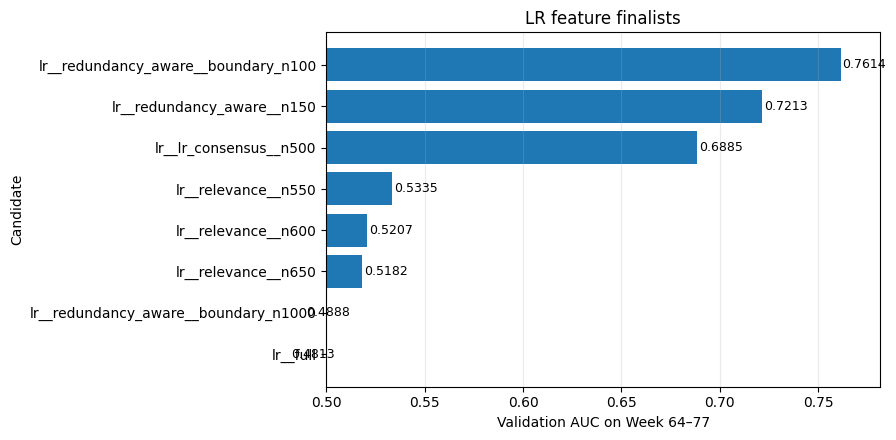

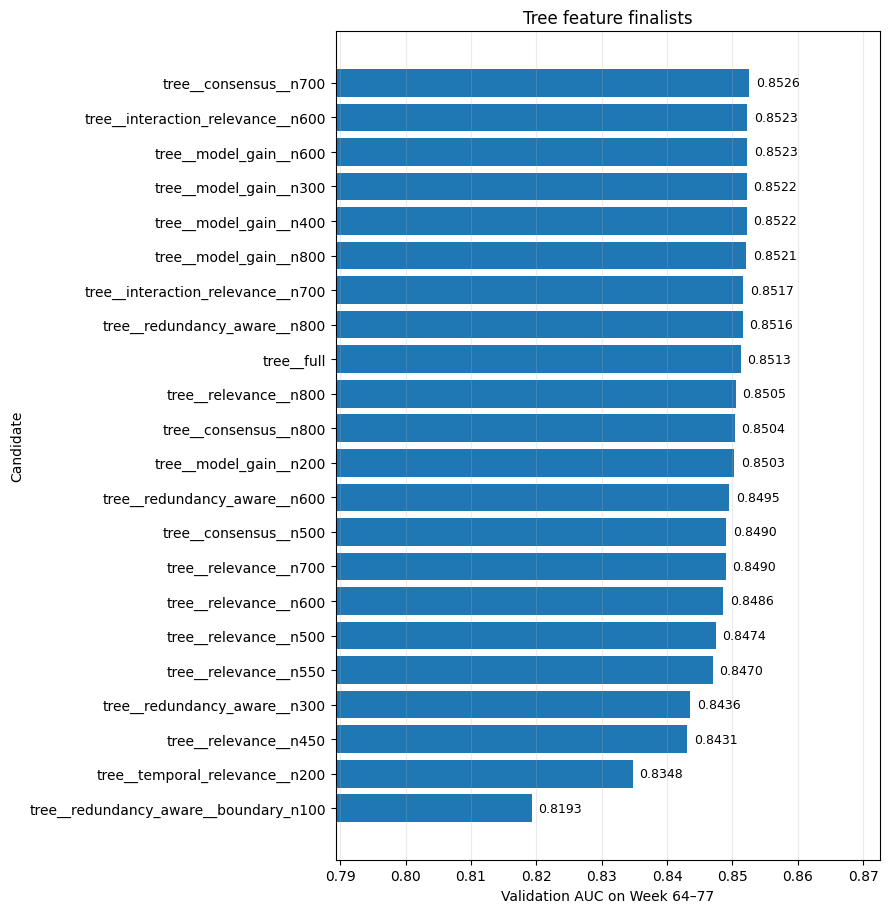

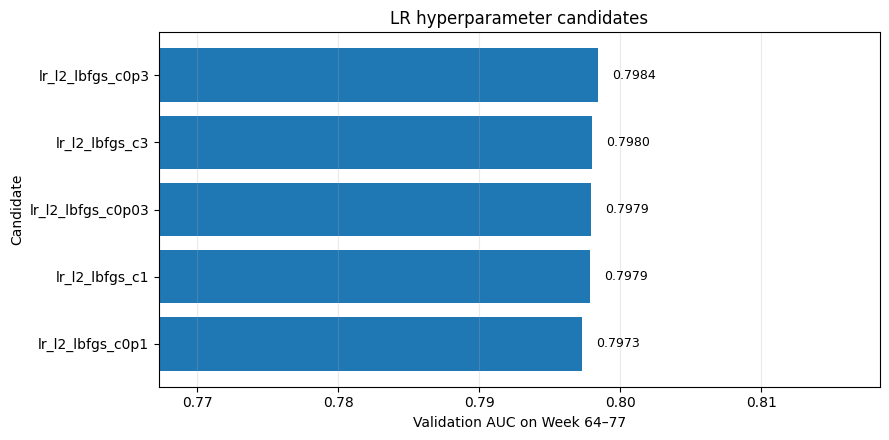

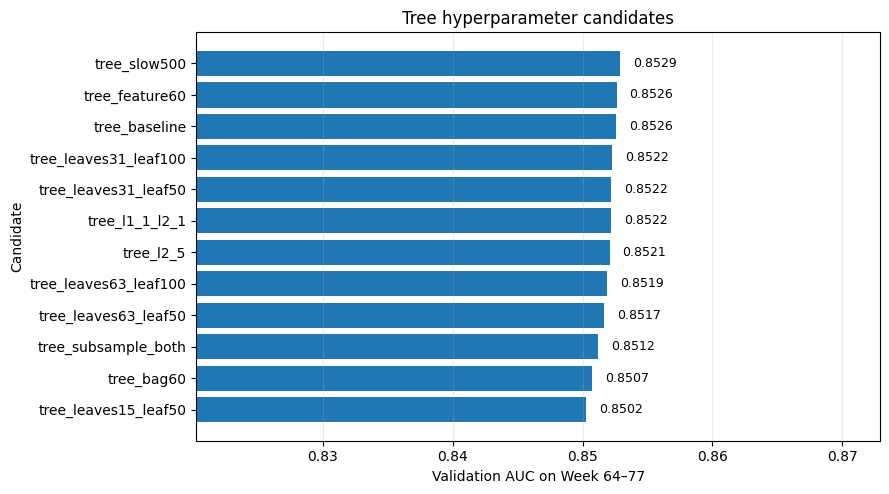

In [8]:
#@title 第 7 步：画图（坐标轴写清楚）
from matplotlib import font_manager as fm

font_candidates = []
for p in fm.findSystemFonts():
    low = Path(p).name.lower()
    if any(
        key in low
        for key in [
            "notosanscjk",
            "wqy",
            "wenquanyi",
            "simhei",
            "msyh",
            "pingfang",
        ]
    ):
        font_candidates.append(p)

if font_candidates:
    ZH_FONT = fm.FontProperties(
        fname=font_candidates[0]
    )
    USE_CN = True
else:
    ZH_FONT = None
    USE_CN = False
    print(
        "当前环境没有完整中文字体，"
        "图表自动使用英文标签，避免缺字警告。"
    )

plt.rcParams["axes.unicode_minus"] = False

def plot_result_table(df, title_cn, title_en):
    d = df.sort_values("AUC", ascending=True)

    fig, ax = plt.subplots(
        figsize=(9, max(4.5, len(d) * 0.42))
    )

    bars = ax.barh(
        d["candidate"],
        d["AUC"],
    )

    if USE_CN:
        ax.set_title(
            title_cn,
            fontproperties=ZH_FONT,
        )
        ax.set_xlabel(
            "Week 64–77 验证集 AUC",
            fontproperties=ZH_FONT,
        )
        ax.set_ylabel(
            "候选模型",
            fontproperties=ZH_FONT,
        )
    else:
        ax.set_title(title_en)
        ax.set_xlabel("Validation AUC on Week 64–77")
        ax.set_ylabel("Candidate")

    lower = max(
        0.5,
        float(d["AUC"].min()) - 0.03,
    )
    upper = min(
        1.0,
        float(d["AUC"].max()) + 0.02,
    )
    ax.set_xlim(lower, upper)

    ax.grid(
        axis="x",
        alpha=0.25,
    )

    for bar, value in zip(
        bars,
        d["AUC"],
    ):
        ax.text(
            value + 0.001,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.4f}",
            va="center",
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

plot_result_table(
    lr_feature_table,
    "LR：Feature finalists 验证集比较",
    "LR feature finalists",
)

plot_result_table(
    tree_feature_table,
    "Tree：Feature finalists 验证集比较",
    "Tree feature finalists",
)

plot_result_table(
    lr_param_result,
    "LR：全部参数候选验证集比较",
    "LR hyperparameter candidates",
)

plot_result_table(
    tree_param_result,
    "Tree：全部参数候选验证集比较",
    "Tree hyperparameter candidates",
)


## 实验 5：冻结选定配置与下游接口

本阶段完成后，固定根据 Week 64–77 选定的配置，不应再针对该时间段反复扩大搜索。

Notebook 14 只输出：

```text
最终 LR feature subset
最终 LR hyperparameters

最终 Tree feature subset
最终 Tree hyperparameters
```

之后 Notebook 15 只负责：

```text
原始 baseline
vs
Feature Selection 后
vs
最终调参后
```

进行统一比较。

### 重要边界

从这一刻开始：

```text
Week 64–77
已经完成它的职责
→ 不能再反复看结果后继续改模型

Week 78–91
仍然完全 untouched
→ 最终 OOT
```

如根据 OOT 结果重新调参，则该 OOT 窗口不再能作为同一轮独立测试的无偏性能评估。


In [9]:
#@title 第 8 步：冻结 NB14 最终结果，交给 Notebook 15

feature_result.to_csv(
    NB14_DIR / "feature_selection_validation_results.csv",
    index=False,
)

lr_param_result.to_csv(
    NB14_DIR / "lr_parameter_validation_results.csv",
    index=False,
)

tree_param_result.to_csv(
    NB14_DIR / "tree_parameter_validation_results.csv",
    index=False,
)

with open(
    NB14_DIR / "selected_features_lr_nb14.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        selected_lr_features,
        f,
        ensure_ascii=False,
        indent=2,
    )

with open(
    NB14_DIR / "selected_features_tree_nb14.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        selected_tree_features,
        f,
        ensure_ascii=False,
        indent=2,
    )

with open(
    NB14_DIR / "selected_engineered_specs_lr_nb14.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        compatible_specs,
        f,
        ensure_ascii=False,
        indent=2,
    )

with open(
    NB14_DIR / "final_lr_config_nb14.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        FINAL_LR_CONFIG,
        f,
        ensure_ascii=False,
        indent=2,
    )

with open(
    NB14_DIR / "final_tree_config_nb14.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        FINAL_TREE_CONFIG,
        f,
        ensure_ascii=False,
        indent=2,
    )

handoff = {
    "protocol": {
        "train_weeks": [0, 63],
        "validation_weeks": [64, 77],
        "oot_weeks": [78, 91],
        "oot_used_in_nb14": False,
    },
    "lr": {
        "feature_winner": LR_FEATURE_WINNER,
        "feature_count": len(selected_lr_features),
        "compatible_engineered_specs": len(compatible_specs),
        "parameter_winner": LR_PARAM_WINNER,
        "final_config": FINAL_LR_CONFIG,
        "validation_auc": float(
            lr_param_result.iloc[0]["AUC"]
        ),
    },
    "tree": {
        "feature_winner": TREE_FEATURE_WINNER,
        "feature_count": len(selected_tree_features),
        "parameter_winner": TREE_PARAM_WINNER,
        "final_config": FINAL_TREE_CONFIG,
        "validation_auc": float(
            tree_param_result.iloc[0]["AUC"]
        ),
    },
}

with open(
    NB14_DIR / "nb14_handoff_to_nb15.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        handoff,
        f,
        ensure_ascii=False,
        indent=2,
    )

print("=" * 90)
print("NB14 FINAL HANDOFF")
print("=" * 90)
print(json.dumps(
    handoff,
    ensure_ascii=False,
    indent=2,
))
print()
print("结果目录：", NB14_DIR)
print("OOT 78–91：未读取")


NB14 FINAL HANDOFF
{
  "protocol": {
    "train_weeks": [
      0,
      63
    ],
    "validation_weeks": [
      64,
      77
    ],
    "oot_weeks": [
      78,
      91
    ],
    "oot_used_in_nb14": false
  },
  "lr": {
    "feature_winner": "lr__redundancy_aware__boundary_n100",
    "feature_count": 100,
    "compatible_engineered_specs": 4,
    "parameter_winner": "lr_l2_lbfgs_c0p3",
    "final_config": {
      "candidate": "lr_l2_lbfgs_c0p3",
      "solver": "lbfgs",
      "penalty": "l2",
      "C": 0.3,
      "max_iter": 1000,
      "tol": 0.0001
    },
    "validation_auc": 0.7984017271483004
  },
  "tree": {
    "feature_winner": "tree__consensus__n700",
    "feature_count": 700,
    "parameter_winner": "tree_slow500",
    "final_config": {
      "learning_rate": 0.03,
      "num_leaves": 31,
      "min_data_in_leaf": 20,
      "feature_fraction": 0.8,
      "bagging_fraction": 0.8,
      "bagging_freq": 1,
      "lambda_l1": 0.0,
      "lambda_l2": 1.0,
      "num_boost_ro

## 6. 结果摘要、交付文件与局限性

实际保存的执行输出显示，本轮在 Week 64–77 上选择：

| Model Family | Selected Feature Subset | Selected Hyperparameters | Validation AUC |
|---|---|---|---:|
| Logistic Regression | `lr__redundancy_aware__boundary_n100`（100 sources） | L2 + LBFGS, `C=0.3` | 0.798402 |
| LightGBM | `tree__consensus__n700`（700 features） | `tree_slow500` | 0.852902 |

以上为**选模窗口成绩**，不是 Week 78–91 OOT 结果。LR 使用新 subset 后，NB11 的 30 个 engineered specs 中仅有 4 个满足 source compatibility。不同 Notebook 中结果不能脱离其输入特征、训练配置和验证信息暴露情况直接比较。

主要下游文件：

```text
selected_features_lr_nb14.json
selected_features_tree_nb14.json
selected_engineered_specs_lr_nb14.json
final_lr_config_nb14.json
final_tree_config_nb14.json
nb14_handoff_to_nb15.json
```

**后续评估边界：** F1–F4 负责 development 内候选评估，Week 64–77 已用于最终选择，Week 78–91 留作独立时间外评估。没有保存的 OOT 结果前，不应声称该模型已验证最终时间外泛化表现。
